# **Lab 6: Euler’s Method for Ordinary Differential Equations**<br>

Ordinary Differential Equation (ODE) is a differential equation consisting of one or more functions of a single independent variable and the derivatives of those functions. Finding derivatives analytically is a complex procedure, involving a lot of rules. Computers and calculators find derivatives using some sort of numerical methods. Here, our target is to estimate a function at discrete points given its differential equation using the **Euler's method**. An important thing to note here is that this method can only solve first order ODE of the form $$ \frac{dy}{dx}=f(x,y), y(x_0)=y_0 $$

In today's lab, we will be implementing the **Euler's method** for solving a first order ODE in python. Refer to the example in the lecture slide.

The following is the problem you need to solve.
<br>
A ball at $1200K$ is allowed to cool down in air at an ambient temperature of $300K$. Assuming heat is lost only due to radiation, the differential equation for the temperature of the ball is given by $$\frac{d\theta}{dt}=-2.2067\times 10^{-12} (\theta^4 - 81 \times 10^8), y(0)=1,\theta(0)=1200K$$ where $\theta$ is in $K$ and $t$ in seconds. Find the temperature at $t=480$ seconds using Euler’s method. Assume a step size of $h=240$ seconds. Compare with the exact value.

##Task 1
Implement the bivariate function $f(t, \theta)$ and the algorthim for Euler's method.
$$\theta_{i+1} = \theta_i + f(t_i, \theta_i)(t_{i+1}-t_i)$$ where $h=t_{i+1}-t_i$ is the step size.

In [ ]:
import numpy as np

def f(t, theta):
    #Write your code here.
    res = -2.2067*(10**(-12))*(theta**(4) - 81 *10**(8))
    return res

def Euler(t_0, y_0, h, t):
    #Write your code here.
    t_temp = t_0
    theta_0 = y_0
    theta = 0
    time_vals = [t_0]
    theta_vals = [theta_0]
    while(t_temp<t):
        theta = theta_0 + f(t_temp, theta_0)*(h)
        theta_0 = theta
        t_temp = t_temp + h

        time_vals.append(t_temp)
        theta_vals.append(theta)

    return theta, time_vals, theta_vals

In [ ]:
print(f'Temperature at t = 480s with step size h = 240s is {Euler(0,1200,240,480)[0]}K')

Temperature at t = 480s with step size h = 240s is 110.31739981426284K


Your answer should be $\approx 110.32K$.

##Task 2
Calculate the exact solution of the ODE. It is the root of the nonlinear equation
$$ 0.92593\ln\left( \frac{\theta-300}{\theta+300} \right) - 1.8519\tan^{-1}(0.333\times10^{-2}\theta) = -0.22067\times 10^{-3}t - 2.9282 $$ at $t=480$ seconds.

You can use your own root-finding algorithm or you can use the `fsolve()` function from the `scipy` package. (https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.fsolve.html)

In [ ]:
# Write your code here.
from scipy.optimize import fsolve

def nonlinear_eq(theta, t=480):
  res = 0.92593*np.log((theta-300)/(theta+300)) - 1.8519*np.arctan(0.333*(10**(-2))*theta) + (0.22067*(10**(-3))*t + 2.9282)
  return res

def ODE(theta_0):
  res = fsolve(nonlinear_eq, theta_0)
  return res

print(f'Temperature at t = 480s is {ODE(1200)}K')

Temperature at t = 480s is [646.49586666]K


The exact value should be $\theta_{exact} \approx 647.57K$.

Now, approximate the value of $\theta(480)$ using different step sizes, such as $480, 240, 120, 60,$ and $30$. Calculate the Global Truncation Error $E_t$ and the Absolute Relative True Error $|\epsilon_t|\%$ in each case.

In [ ]:
# Write your code here.
global_error = []
truncation_error = []
step_sizes = [480, 240, 120, 60, 30]
thetas = []
exact_val = ODE(1200)

for i in step_sizes:
  theta = Euler(0,1200,i,480)[0]
  error = abs(theta - exact_val)

  thetas.append(theta)
  global_error.append(error)
  truncation_error.append((error*100)/abs(exact_val))

print(f'Global Truncation Error: {global_error}')
print(f'Absolute Relative True Error: {truncation_error}')

Global Truncation Error: [array([1634.30651466]), array([536.17846685]), array([99.72088954]), array([31.52972579]), array([13.72920405])]
Absolute Relative True Error: [array([252.79458059]), array([82.9361013]), array([15.42483018]), array([4.87701893]), array([2.12363369])]


Your values should approximately match the values of this table.
<br>
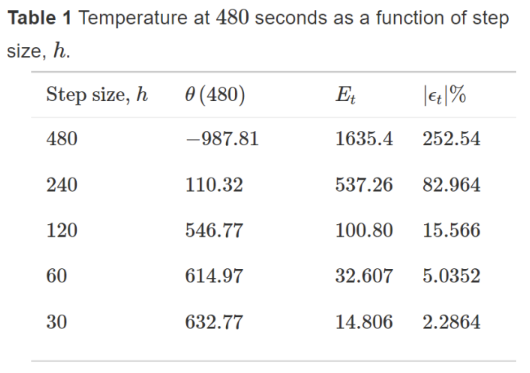

## Task 3
Generate a Temperature $\theta$ vs Step size $h$ plot which portrays the effect of step size in Euler's method. Use a different marker to represent the exact value.

temperatures:  [-987.8106479999997, 110.31739981426284, 546.7749771189773, 614.9661408677375, 632.7666626119995]
step_sizes:  [480, 240, 120, 60, 30]


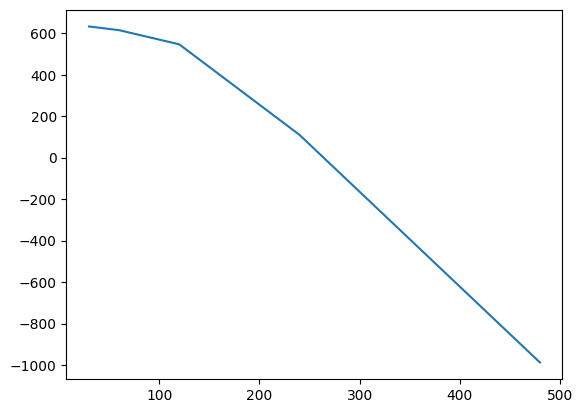

In [ ]:
# Write your code here.
import matplotlib.pyplot as plt

print('temperatures: ', thetas)
print('step_sizes: ', step_sizes)

plt.figure
plt.plot(step_sizes, thetas)
plt.show()

Your graph should look something like,
<br>
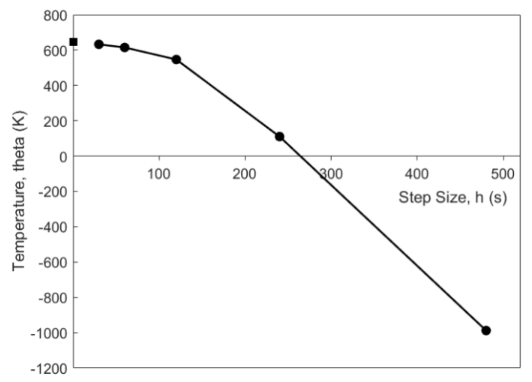

Genrerate a Temperature $\theta$ vs Time $t$ plot that compares the Euler's method approximations for different step sizes with the exact solution.

[array([1192.49164118]), array([1188.05081579]), array([1183.67592989]), array([1179.36528895]), array([1175.11726003]), array([1170.93026892]), array([1166.80279739]), array([1162.73338063]), array([1158.72060486]), array([1154.76310501]), array([1150.8595626]), array([1147.00870362]), array([1143.20929669]), array([1139.46015114]), array([1135.76011532]), array([1132.10807496]), array([1128.50295158]), array([1124.94370103]), array([1121.42931206]), array([1117.95880501]), array([1114.53123051]), array([1111.1456683]), array([1107.80122607]), array([1104.49703836]), array([1101.23226552]), array([1098.00609272]), array([1094.817729]), array([1091.66640639]), array([1088.551379]), array([1085.47192226]), array([1082.42733209]), array([1079.41692418]), array([1076.44003324]), array([1073.49601237]), array([1070.58423236]), array([1067.70408107]), array([1064.85496286]), array([1062.03629799]), array([1059.2475221]), array([1056.48808562]), array([1053.75745337]), array([1051.05510398])

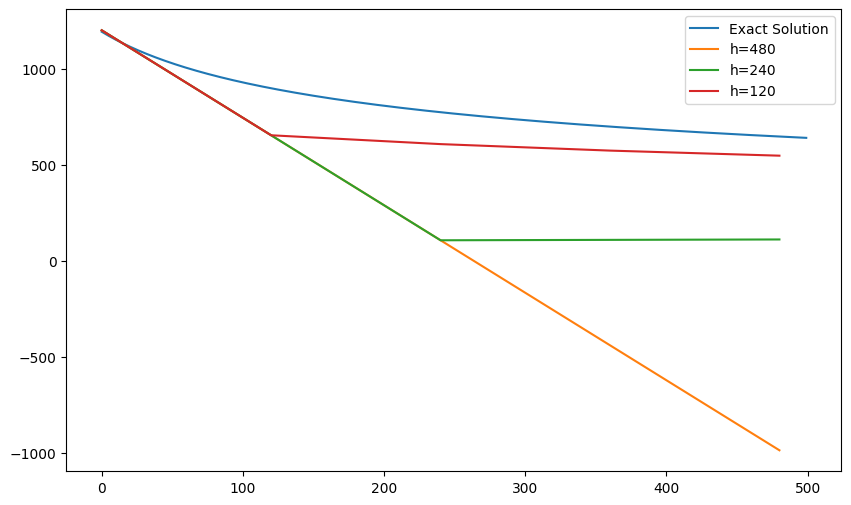

In [ ]:
times = np.arange(0, 500)
exact_theta = []
temp_ = []

for i in times:
  theta = fsolve(nonlinear_eq, 800, args=(i))
  exact_theta.append(theta)

print(exact_theta)

plt.figure(figsize=(10, 6))
plt.plot(times, exact_theta, label='Exact Solution')

theta, times, thetas = Euler(0,1200,480,480)
plt.plot(times, thetas, label='h=480')

theta, times, thetas = Euler(0,1200,240,480)
plt.plot(times, thetas, label='h=240')

theta, times, thetas = Euler(0,1200,120,480)
plt.plot(times, thetas, label='h=120')

plt.legend()
plt.show()

Your graph should look something like,
<br>
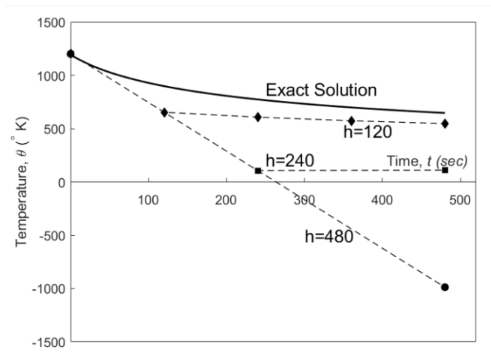